In [24]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import davies_bouldin_score
import seaborn as sns
import cartopy.crs as cors
from yellowbrick.cluster import SilhouetteVisualizer
from sklearn.decomposition import PCA
import glob
import os
import re 

In [25]:
def read_multi_excel(path, index_name):
    # baca semua file format xlsx
    files = glob.glob(os.path.join(path, '*.xlsx'))
    li = []
    
    for filename in files:
        # print(filename)
        
        df = pd.read_excel(filename, index_col=index_name)
        li.append(df)
    
    # concat dg index kabupaten, pastikan sama persis untuk semua file yg dibaca
    df = pd.concat(li, axis=1)
    
    return df

# fungsi untuk menggantikan unnamed 1 menjadi kolom sesuai data BPS
def process_bps_cols(new_df):
    new_header = []

    for i in range(0, len(new_df.columns)):
        # keterangan variabel
        first_row = str(new_df.iloc[0, i])
        first_row = re.sub(r"\[Metode Baru\] ", r"", first_row)
        
        # tahun yang terbaca sebagai baris kedua
        second_row = str(new_df.iloc[1, i])
        
        new_col = f"{first_row} {second_row}"
        new_header.append(new_col)

    new_df.columns = new_header
    new_df = new_df.iloc[2:] # buang dua baris pertama lama

    return new_df

In [26]:
import numpy as np

features_path = [
    'datasets/HLS', # Harapan Lama Sekolah (Tahun)
    'datasets/RLS', # Rata-rata Lama Sekolah (Tahun)
    'datasets/UHH', # Umur Harapan Hidup Saat Lahir (UHH) (Tahun)
    'datasets/Pengeluaran_Per_Kapita_PPP', # Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun)
]

bukan_kabupaten = [
    'ACEH', 'SUMATERA UTARA', 'SUMATERA BARAT', 'RIAU', 'JAMBI',
    'SUMATERA SELATAN', 'BENGKULU', 'LAMPUNG', 'KEP. BANGKA BELITUNG', 'KEPULAUAN RIAU',
    'DKI JAKARTA', 'JAWA BARAT', 'JAWA TENGAH', 'D I YOGYAKARTA', 'JAWA TIMUR',
    'BANTEN', 'BALI', 'NUSA TENGGARA BARAT', 'NUSA TENGGARA TIMUR', 'KALIMANTAN BARAT',
    'KALIMANTAN TENGAH', 'KALIMANTAN SELATAN', 'KALIMANTAN TIMUR', 'KALIMANTAN UTARA', 'SULAWESI UTARA',
    'SULAWESI TENGAH', 'SULAWESI SELATAN', 'SULAWESI TENGGARA', 'GORONTALO', 'SULAWESI BARAT',
    'MALUKU', 'MALUKU UTARA', 'PAPUA BARAT', 'PAPUA BARAT DAYA', 'PAPUA',
    'PAPUA SELATAN', 'PAPUA TENGAH', 'PAPUA PEGUNUNGAN'
]

# relative path dataset gabungan
dataset_gabungan = "datasets/535240039.xlsx";

def combine_features_to_df(features_path):
    index_name = 'Provinsi/Kabupaten/Kota/Indonesia'
    dfs = []

    for features in features_path:
        val_df = read_multi_excel(features, index_name)
        val_df = process_bps_cols(val_df)
        val_df = val_df.drop(index=bukan_kabupaten)

        # data sebelum pemekaran 
        df_prov_lama = val_df[~val_df.index.duplicated(keep='first')]
        # data setelah pemekaran jadi 38 provinsi
        df_prov_baru = val_df[val_df.index.duplicated(keep='first')]
        # print(df_prov_baru)
    
        # replace nilai strip dg nilai yg ada di data pasca pemekaran (naive)
        for idx in df_prov_baru.index:
            if idx in df_prov_lama.index:
                mask = df_prov_lama.loc[idx].astype(str).str.strip() == "-"
                df_prov_lama.loc[idx, mask] = df_prov_baru.loc[idx, mask].values

        val_df = df_prov_lama.copy()

        # handle missing value dg backward interpolate (tahun awal ada nan)
        val_df = val_df.replace("-", np.nan)
        val_df = val_df.astype(float).interpolate(method='linear', limit_direction='backward', axis=1)

        if os.path.isfile(dataset_gabungan):
            with pd.ExcelWriter(dataset_gabungan, mode='a', if_sheet_exists='replace') as writer:  
                val_df.to_excel(writer, sheet_name=features.split("/")[1], index=True)
        else:
            val_df.to_excel(dataset_gabungan, sheet_name=features.split("/")[1], index=True)

        dfs.append(val_df)

    return dfs

dfs = combine_features_to_df(features_path)
combined = pd.concat(dfs, axis=1, join='inner')

# buat sheet gabungan
if os.path.isfile(dataset_gabungan):
    with pd.ExcelWriter(dataset_gabungan, mode='a', if_sheet_exists='replace') as writer:  
        combined.to_excel(writer, sheet_name='Gabungan', index=True)
else:
    combined.to_excel(dataset_gabungan, sheet_name='Gabungan', index=True)


In [27]:
# df_prov_baru = ipm[0][ipm[0].index.duplicated(keep='first')]
# print(ipm[0].index[ipm[0].index.duplicated()].unique())
# ipm[0] = ipm[0][~ipm[0].index.duplicated(keep='first')]

# ipm[0]

In [28]:
# df_prov_baru = df_prov_baru.loc[:, ~df_prov_baru.astype(str).apply(lambda x: x.str.strip() == "-").any()]
# df_prov_baru

In [29]:
df = pd.read_excel('datasets/535240039.xlsx', sheet_name='Gabungan', index_col='Provinsi/Kabupaten/Kota/Indonesia')
print(df.shape)
df.tail(2)

(515, 60)


,Harapan Lama Sekolah (Tahun) 2010,Harapan Lama Sekolah (Tahun) 2011,Harapan Lama Sekolah (Tahun) 2012,Harapan Lama Sekolah (Tahun) 2013,Harapan Lama Sekolah (Tahun) 2014,Harapan Lama Sekolah (Tahun) 2015,Harapan Lama Sekolah (Tahun) 2016,Harapan Lama Sekolah (Tahun) 2017,Harapan Lama Sekolah (Tahun) 2018,Harapan Lama Sekolah (Tahun) 2019,...,Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun) 2015,Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun) 2016,Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun) 2017,Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun) 2018,Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun) 2019,Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun) 2020,Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun) 2021,Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun) 2022,Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun) 2023,Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun) 2024
Provinsi/Kabupaten/Kota/Indonesia,,,,,,,,,,,,,,,,,,,,,
Kota Jayapura,13.64,13.77,13.91,13.95,14.06,14.16,14.61,14.98,14.99,15.00,...,14249,14319,14781,14922,15176,14763,14937,15189,15272,15408
INDONESIA,11.29,11.44,11.68,12.10,12.39,12.55,12.72,12.85,12.91,12.95,...,10150,10420,10664,11059,11299,11013,11156,11479,11899,12341


In [30]:
indonesia = df.iloc[df.shape[0] - 1:] # ambil buat keperluan visualisasi nanti
df_ipm = df.iloc[:-1]
print(df_ipm.shape)
df_ipm.tail()

(514, 60)


,Harapan Lama Sekolah (Tahun) 2010,Harapan Lama Sekolah (Tahun) 2011,Harapan Lama Sekolah (Tahun) 2012,Harapan Lama Sekolah (Tahun) 2013,Harapan Lama Sekolah (Tahun) 2014,Harapan Lama Sekolah (Tahun) 2015,Harapan Lama Sekolah (Tahun) 2016,Harapan Lama Sekolah (Tahun) 2017,Harapan Lama Sekolah (Tahun) 2018,Harapan Lama Sekolah (Tahun) 2019,...,Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun) 2015,Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun) 2016,Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun) 2017,Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun) 2018,Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun) 2019,Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun) 2020,Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun) 2021,Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun) 2022,Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun) 2023,Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun) 2024
Provinsi/Kabupaten/Kota/Indonesia,,,,,,,,,,,,,,,,,,,,,
Puncak,2.84,3.21,3.73,4.04,4.13,4.47,4.48,4.66,4.93,5.19,...,5118,5181,5413,5506,5702,5378,5412,5583,5975,6363
Dogiyai,7.85,8.14,8.77,8.99,9.41,9.58,9.87,10.12,10.13,10.57,...,5120,5190,5375,5522,5709,5373,5415,5705,6182,6755
Intan Jaya,4.12,4.51,5.40,5.74,6.00,6.28,6.52,6.76,7.11,7.36,...,5015,5038,5293,5440,5593,5283,5328,5624,6140,6463
Deiyai,9.06,9.23,9.40,9.57,9.75,9.76,9.77,9.78,9.79,9.80,...,4320,4383,4597,4761,4958,4632,4673,4808,5104,5509
Kota Jayapura,13.64,13.77,13.91,13.95,14.06,14.16,14.61,14.98,14.99,15.00,...,14249,14319,14781,14922,15176,14763,14937,15189,15272,15408


In [31]:
indonesia.head()

,Harapan Lama Sekolah (Tahun) 2010,Harapan Lama Sekolah (Tahun) 2011,Harapan Lama Sekolah (Tahun) 2012,Harapan Lama Sekolah (Tahun) 2013,Harapan Lama Sekolah (Tahun) 2014,Harapan Lama Sekolah (Tahun) 2015,Harapan Lama Sekolah (Tahun) 2016,Harapan Lama Sekolah (Tahun) 2017,Harapan Lama Sekolah (Tahun) 2018,Harapan Lama Sekolah (Tahun) 2019,...,Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun) 2015,Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun) 2016,Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun) 2017,Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun) 2018,Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun) 2019,Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun) 2020,Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun) 2021,Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun) 2022,Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun) 2023,Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun) 2024
Provinsi/Kabupaten/Kota/Indonesia,,,,,,,,,,,,,,,,,,,,,
INDONESIA,11.29,11.44,11.68,12.1,12.39,12.55,12.72,12.85,12.91,12.95,...,10150,10420,10664,11059,11299,11013,11156,11479,11899,12341


In [32]:
from sklearn.preprocessing import RobustScaler
from sklearn.decomposition import PCA

robust = RobustScaler()

df_index_copy = df_ipm.index
df_cols_copy = df_ipm.columns

df_ipm = pd.DataFrame(robust.fit_transform(df_ipm))
df_ipm.head()

,0,1,2,3,4,5,6,7,8,9,...,50,51,52,53,54,55,56,57,58,59
0,0.996154,0.964750,0.750000,0.548330,0.393443,0.345588,0.389961,0.443992,0.395257,0.569672,...,-0.936280,-0.936266,-0.961285,-1.008807,-0.975946,-0.976192,-0.969316,-0.979194,-0.965268,-0.984686
1,0.965385,1.098330,1.344203,1.377856,1.245902,1.397059,1.316602,1.299389,1.217391,1.217213,...,-0.525246,-0.446300,-0.454968,-0.474966,-0.499604,-0.452587,-0.451669,-0.473311,-0.456566,-0.444171
2,0.919231,0.853432,0.677536,0.787346,0.590164,0.647059,0.745174,0.908350,1.106719,1.307377,...,-0.647201,-0.661743,-0.671122,-0.670158,-0.666719,-0.652086,-0.641176,-0.673108,-0.656069,-0.651020
3,0.980769,0.964750,1.119565,1.159930,0.944262,0.926471,1.077220,1.046843,0.972332,0.963115,...,-0.719148,-0.721143,-0.738936,-0.735539,-0.704700,-0.674360,-0.688871,-0.713941,-0.700068,-0.747672
4,0.296154,0.185529,0.039855,-0.091388,-0.209836,-0.095588,-0.011583,0.256619,0.205534,0.168033,...,-0.518471,-0.524322,-0.542669,-0.555582,-0.536003,-0.522960,-0.514944,-0.431855,-0.437881,-0.435860


In [33]:
# df_ipm.columns = df_cols_copy

pca = PCA(2)
df_ipm = pd.DataFrame(pca.fit_transform(df_ipm), columns=['PC1', 'PC2'])
df_ipm.index = df_index_copy

In [34]:
df_ipm.head()

,PC1,PC2
Provinsi/Kabupaten/Kota/Indonesia,,
Simeulue,-0.000726,-5.933680
Aceh Singkil,1.297387,-4.437340
Aceh Selatan,0.163996,-6.329819
Aceh Tenggara,2.284530,-4.557585
Aceh Timur,-1.416582,-1.393234


In [35]:
import time
kmeans_results = []
kmeans_models = []

cluster_limits = 11

print("K-Means Clustering")
print("-"*64)
for i in range(2, cluster_limits, 1):
    kmeans = KMeans(n_clusters=i, n_init=400, random_state=42)
    kmeans_models.append(kmeans)

    start = time.time()
    label = kmeans.fit_predict(df_ipm)
    end = time.time()

    train_time = end - start
    kmeans_results.append(label)

    silhouette_avg = silhouette_score(df_ipm, label)
    dbi = davies_bouldin_score(df_ipm, label)

    print(f'Hasil evaluasi K-Means dengan jumlah cluster', i)
    print(f'Rata rata nilai silhoutte: {silhouette_avg:.4f}', end='\t')
    print(f'Nilai Davies-Bouldin Index: {dbi:.4f}', end='\t')
    print(f'Waktu komputasi: {train_time:.4f} detik\n')

K-Means Clustering
----------------------------------------------------------------
Hasil evaluasi K-Means dengan jumlah cluster 2
Rata rata nilai silhoutte: 0.4476	Nilai Davies-Bouldin Index: 0.8234	Waktu komputasi: 1.2836 detik

Hasil evaluasi K-Means dengan jumlah cluster 3
Rata rata nilai silhoutte: 0.5040	Nilai Davies-Bouldin Index: 0.6543	Waktu komputasi: 1.6201 detik

Hasil evaluasi K-Means dengan jumlah cluster 4
Rata rata nilai silhoutte: 0.3629	Nilai Davies-Bouldin Index: 0.8242	Waktu komputasi: 1.6514 detik

Hasil evaluasi K-Means dengan jumlah cluster 5
Rata rata nilai silhoutte: 0.3528	Nilai Davies-Bouldin Index: 0.7982	Waktu komputasi: 1.3382 detik

Hasil evaluasi K-Means dengan jumlah cluster 6
Rata rata nilai silhoutte: 0.3528	Nilai Davies-Bouldin Index: 0.7863	Waktu komputasi: 1.3127 detik

Hasil evaluasi K-Means dengan jumlah cluster 7
Rata rata nilai silhoutte: 0.3427	Nilai Davies-Bouldin Index: 0.8704	Waktu komputasi: 1.3356 detik

Hasil evaluasi K-Means dengan juml

In [36]:
from sklearn.cluster import SpectralClustering
import time

spectral_clust_results = []
spectral_clust_models = []

print("Spectral Clustering")
print("-"*64)
for i in range(2, cluster_limits, 1):
    spectral_clust = SpectralClustering(n_clusters=i, n_init=400, random_state=42, affinity='nearest_neighbors', n_neighbors=10)
    spectral_clust_models.append(spectral_clust)

    start = time.time()
    label = spectral_clust.fit_predict(df_ipm)
    end = time.time()

    train_time = end - start
    spectral_clust_results.append(label)

    silhouette_avg = silhouette_score(df_ipm, label)
    dbi = davies_bouldin_score(df_ipm, label)

    print(f'Hasil evaluasi Spectral Clustering dengan jumlah cluster', i)
    print(f'Rata rata nilai silhoutte: {silhouette_avg:.4f}', end='\t')
    print(f'Nilai Davies-Bouldin Index: {dbi:.4f}', end='\t')
    print(f'Waktu komputasi: {train_time:.4f} detik\n')

Spectral Clustering
----------------------------------------------------------------
Hasil evaluasi Spectral Clustering dengan jumlah cluster 2
Rata rata nilai silhoutte: 0.3863	Nilai Davies-Bouldin Index: 0.9438	Waktu komputasi: 1.1124 detik

Hasil evaluasi Spectral Clustering dengan jumlah cluster 3
Rata rata nilai silhoutte: 0.3241	Nilai Davies-Bouldin Index: 1.0576	Waktu komputasi: 1.1213 detik

Hasil evaluasi Spectral Clustering dengan jumlah cluster 4
Rata rata nilai silhoutte: 0.3087	Nilai Davies-Bouldin Index: 0.9828	Waktu komputasi: 1.1325 detik

Hasil evaluasi Spectral Clustering dengan jumlah cluster 5
Rata rata nilai silhoutte: 0.3466	Nilai Davies-Bouldin Index: 0.7756	Waktu komputasi: 1.3664 detik

Hasil evaluasi Spectral Clustering dengan jumlah cluster 6
Rata rata nilai silhoutte: 0.3421	Nilai Davies-Bouldin Index: 0.8081	Waktu komputasi: 1.4481 detik

Hasil evaluasi Spectral Clustering dengan jumlah cluster 7
Rata rata nilai silhoutte: 0.3225	Nilai Davies-Bouldin Index:

In [37]:
from sklearn.cluster import BisectingKMeans

bisect_kmeans_results = []
bisect_kmeans_models = []

print("Bisecting K-Means Clustering")
print("-"*64)
for i in range(2, cluster_limits, 1):
    bisect_kmeans = BisectingKMeans(n_clusters=i, n_init=400, random_state=42)
    bisect_kmeans_models.append(bisect_kmeans)

    start = time.time()
    label = bisect_kmeans.fit_predict(df_ipm)
    end = time.time()

    train_time = end - start
    bisect_kmeans_results.append(label)

    silhouette_avg = silhouette_score(df_ipm, label)
    dbi = davies_bouldin_score(df_ipm, label)

    print(f'Hasil evaluasi Bisecting K-Means dengan jumlah cluster', i)
    print(f'Rata rata nilai silhoutte: {silhouette_avg:.4f}', end='\t')
    print(f'Nilai Davies-Bouldin Index: {dbi:.4f}', end='\t')
    print(f'Waktu komputasi: {train_time:.4f} detik\n')

Bisecting K-Means Clustering
----------------------------------------------------------------
Hasil evaluasi Bisecting K-Means dengan jumlah cluster 2
Rata rata nilai silhoutte: 0.4476	Nilai Davies-Bouldin Index: 0.8234	Waktu komputasi: 1.4087 detik

Hasil evaluasi Bisecting K-Means dengan jumlah cluster 3
Rata rata nilai silhoutte: 0.4813	Nilai Davies-Bouldin Index: 0.6898	Waktu komputasi: 2.5439 detik

Hasil evaluasi Bisecting K-Means dengan jumlah cluster 4
Rata rata nilai silhoutte: 0.3488	Nilai Davies-Bouldin Index: 0.8358	Waktu komputasi: 3.6082 detik

Hasil evaluasi Bisecting K-Means dengan jumlah cluster 5
Rata rata nilai silhoutte: 0.3255	Nilai Davies-Bouldin Index: 0.8907	Waktu komputasi: 4.3358 detik

Hasil evaluasi Bisecting K-Means dengan jumlah cluster 6
Rata rata nilai silhoutte: 0.3045	Nilai Davies-Bouldin Index: 0.8856	Waktu komputasi: 4.9212 detik

Hasil evaluasi Bisecting K-Means dengan jumlah cluster 7
Rata rata nilai silhoutte: 0.3018	Nilai Davies-Bouldin Index: 0.

In [38]:
import warnings
import numpy as np
from sklearn.metrics import silhouette_samples, silhouette_score
import matplotlib.cm as cm
warnings.filterwarnings('ignore', category=FutureWarning)

# visualisasi cluster dan algoritma terbaik
def visualize_silhouette(X, cluster_labels, model):
    model_name = model.__class__.__name__
    X = np.array(X)
    n_clusters = len(np.unique(cluster_labels))

    fig, (ax1, ax2) = plt.subplots(1, 2)
    fig.set_size_inches(18, 7)

    ax1.set_xlim([-0.1,1])
    ax1.set_ylim([0, len(X) + (n_clusters + 1) * 10])

    clusterer = model
    cluster_labels = clusterer.fit_predict(X)

    silhouette_avg = silhouette_score(X, cluster_labels)
    print("For n_clusters =", n_clusters,
    "The average silhouette_score is :", silhouette_avg)

    sample_silhouette_values = silhouette_samples(X, cluster_labels)

    y_lower = 10

    for i in range(n_clusters):
        ith_cluster_silhouette_values = \
            sample_silhouette_values[cluster_labels == i]

        ith_cluster_silhouette_values.sort()

        size_cluster_i = ith_cluster_silhouette_values.shape[0]
        y_upper = y_lower + size_cluster_i

        color_code = abs((float(i) - 0.12) / n_clusters )
        if i == 0:
            color_code = 0
        color = cm.nipy_spectral(color_code)
        ax1.fill_betweenx(np.arange(y_lower, y_upper),
                            0, ith_cluster_silhouette_values,
                            facecolor=color, edgecolor=color, alpha=0.8)

        ax1.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i))
        y_lower = y_upper + 10

    ax1.set_title(f"Silhouette Plot {model_name} dengan k={n_clusters}", fontsize=16)
    ax1.set_xlabel("Nilai Rata-rata Silhouette")
    ax1.set_ylabel("Cluster")

    ax1.axvline(x=silhouette_avg, color="red", linestyle="--")

    ax1.set_yticks([]) # Clear the yaxis Labels / ticks
    ax1.set_xticks([-0.1, 0, 0.2, 0.4, 0.6, 0.8, 1])

    colors_code = np.where(cluster_labels == 0,
                            0,
                            abs((cluster_labels.astype(float) - 0.12) / n_clusters))

    colors = cm.nipy_spectral(colors_code)

    extent = ax1.get_tightbbox(fig.canvas.get_renderer()).transformed(fig.dpi_scale_trans.inverted())
    fig.savefig('images/silhouette_plot.png', dpi=300, bbox_inches=extent)

    ax2.scatter(X[:, 0], X[:, 1], marker='*', s=30, lw=0, alpha=0.8,
                c=colors, edgecolor='k')    

    # karena spectral clustering bukan algo centroid based
    # hitung terlebih dahulu koordinat titik tengah untuk masing2 cluster
    if model_name == 'SpectralClustering':
        # center values for mapping cluster label at plot
        centroids = []
        for i in range(n_clusters):
            cluster_points = X[cluster_labels == i]
        
            cluster_mean = cluster_points.mean(axis=0)
            centroids.append(cluster_mean.tolist())
            centers = np.array(centroids)
        
        # print(centers)

    elif model_name == 'KMeans' or model_name == 'BisectingKMeans': 
        centers = clusterer.cluster_centers_
        # print(centers)

    ax2.scatter(centers[:, 0], centers[:, 1], marker='o',
                c="white", alpha=1, s=200, edgecolor='k')

    for i, c in enumerate(centers):
        ax2.scatter(c[0], c[1], marker='$%d$' % i, alpha=0.8, s=50, edgecolor='k')

    ax2.set_title(f"Visualisasi Scatter Plot {model_name} dengan k={n_clusters}", fontsize=16)
    ax2.set_xlabel("Dimensi Pertama PCA (PC1)")
    ax2.set_ylabel("Dimensi Kedua PCA (PC2)")

    extent = ax2.get_tightbbox(fig.canvas.get_renderer()).transformed(fig.dpi_scale_trans.inverted())
    fig.savefig('images/scatter_plot.png', dpi=300, bbox_inches=extent)

    # plt.suptitle((f"Silhouette analysis for {model_name} clustering on sample data "
    #                 "with n_clusters = %d" % n_clusters),
    #                 fontsize=14, fontweight='bold')

    plt.show()

For n_clusters = 3 The average silhouette_score is : 0.5040366626428252


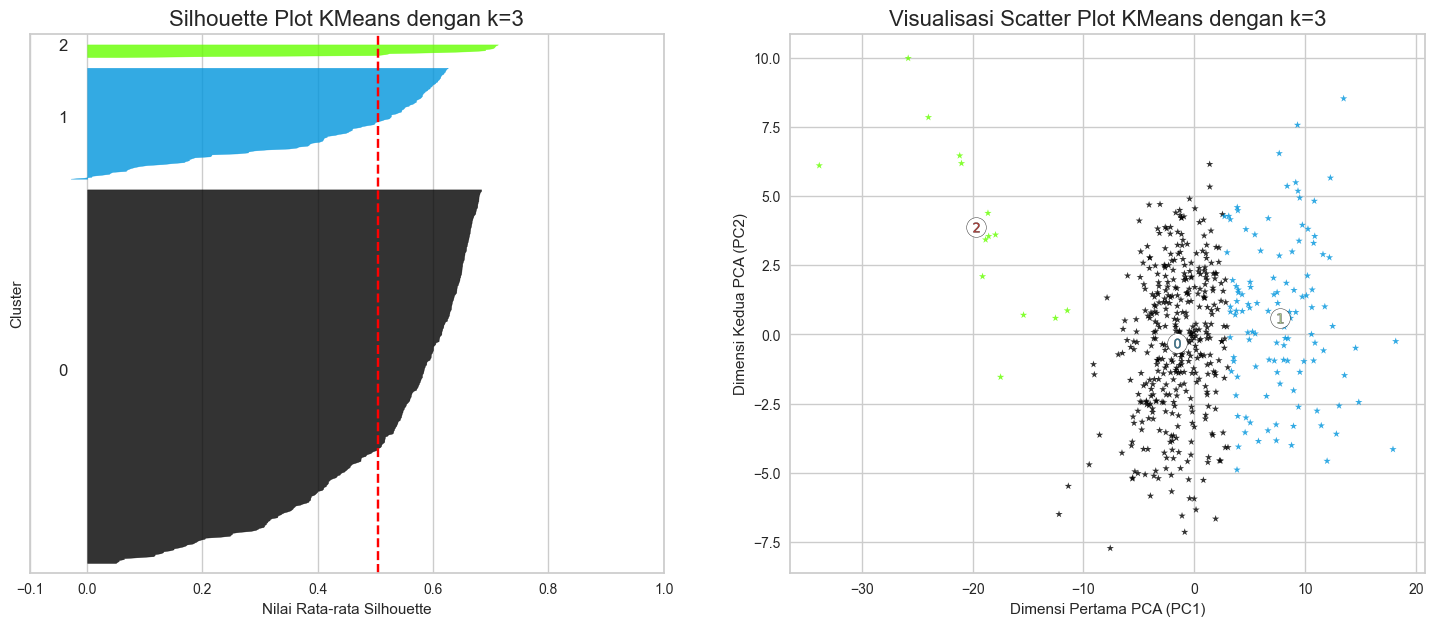

In [39]:
# ambil model terbaik
visualize_silhouette(df_ipm, kmeans_results[1], kmeans_models[1])

In [ ]:
import geopandas as gpd

gdf = gpd.read_file('shp\BATAS KABUPATEN KOTA DESEMBER 2019 DUKCAPIL.shp')

gdf = gdf.iloc[1:]

# dapatkan kab kota untuk penyesuaian nama
kabupaten_kota = gdf['KAB_KOTA']

for kab in kabupaten_kota:
    print(kab)

ACEH BARAT
ACEH BARAT DAYA
ACEH BESAR
ACEH JAYA
ACEH SELATAN
ACEH SINGKIL
ACEH TAMIANG
ACEH TENGAH
ACEH TENGGARA
ACEH TIMUR
ACEH UTARA
AGAM
ALOR
ASAHAN
ASMAT
BADUNG
BALANGAN
BANDUNG
BANDUNG BARAT
BANGGAI
BANGGAI KEPULAUAN
BANGGAI LAUT
BANGKA
BANGKA BARAT
BANGKA SELATAN
BANGKA TENGAH
BANGKALAN
BANGLI
BANJAR
BANJARNEGARA
BANTAENG
BANTUL
BANYUASIN
BANYUMAS
BANYUWANGI
BARITO KUALA
BARITO SELATAN
BARITO TIMUR
BARITO UTARA
BARRU
BATANG
BATANGHARI
BATU BARA
BEKASI
BELITUNG
BELITUNG TIMUR
BELU
BENER MERIAH
BENGKALIS
BENGKAYANG
BENGKULU SELATAN
BENGKULU TENGAH
BENGKULU UTARA
BERAU
BIAK NUMFOR
BIMA
BINTAN
BIREUEN
BLITAR
BLORA
BOALEMO
BOGOR
BOJONEGORO
BOLAANG MONGONDOW
BOLAANG MONGONDOW SELATAN
BOLAANG MONGONDOW TIMUR
BOLAANG MONGONDOW UTARA
BOMBANA
BONDOWOSO
BONE
BONE BOLANGO
BOVEN DIGOEL
BOYOLALI
BREBES
BULELENG
BULUKUMBA
BULUNGAN
BUNGO
BUOL
BURU
BURU SELATAN
BUTON
BUTON SELATAN
BUTON TENGAH
BUTON UTARA
CIAMIS
CIANJUR
CILACAP
CIREBON
DAIRI
DEIYAI
DELI SERDANG
DEMAK
DHARMASRAYA
DOGIYAI
DOMPU
DON

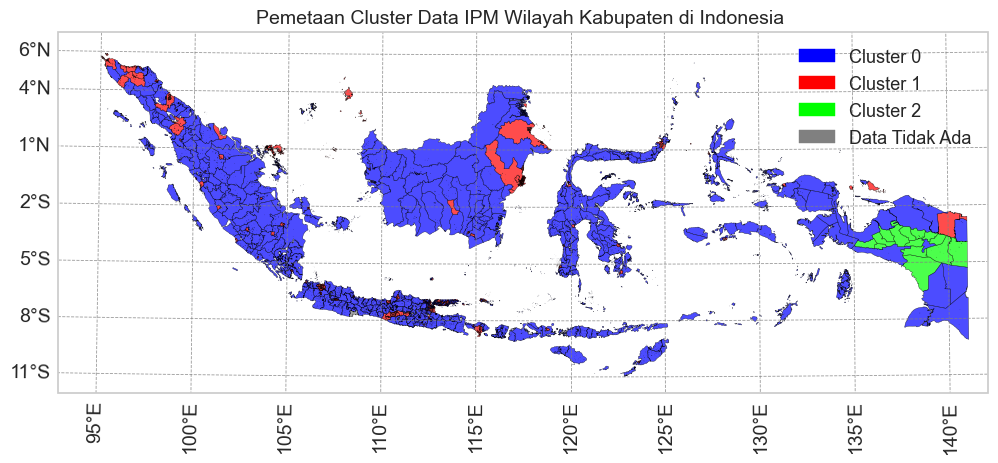

In [41]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import geopandas as gpd
import matplotlib.ticker as mticker
from cartopy.mpl. gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
from matplotlib_map_utils.core.north_arrow import NorthArrow, north_arrow
from matplotlib_map_utils.core.scale_bar import ScaleBar, scale_bar
import matplotlib.patches as mpatches

warnings.filterwarnings('ignore')
excel_path = 'datasets/535240039.xlsx'

indo_crs = ccrs.AlbersEqualArea(
    central_longitude=120,
    central_latitude=0,
    standard_parallels=(-6, 10)
)
fig = plt.figure(figsize=(12, 8))
ax = plt.axes(projection=indo_crs)

ax.set_extent([93, 142, -12, 7], crs=ccrs.PlateCarree())

# https://www.indonesia-geospasial.com/2020/04/download-shapefile-shp-batas.html
gdf = gpd.read_file("shp\BATAS KABUPATEN KOTA DESEMBER 2019 DUKCAPIL.shp")

gdf = gdf.iloc[1:]

gdf = gdf.to_crs(indo_crs)

df_visualize = df.iloc[:-1]

kab_kota_pair  = pd.read_excel(excel_path, sheet_name='Penyesuaian_IndoGeospasial')

kamus_penyesuaian = kab_kota_pair.set_index('KAB_KOTA_BPS')['KAB_KOTA'].to_dict()

df_visualize['Cluster'] = kmeans_results[1] # hasil terbaik

if os.path.isfile(excel_path):
    with pd.ExcelWriter(excel_path, mode='a', if_sheet_exists='replace') as writer:  
        df_visualize.to_excel(writer, sheet_name='Hasil', index=True)
else:
    df_visualize.to_excel(excel_path, sheet_name='Hasil', index=True)

df_reset = df_visualize.reset_index()
df_reset['Provinsi/Kabupaten/Kota/Indonesia'] = df_reset['Provinsi/Kabupaten/Kota/Indonesia'].replace(kamus_penyesuaian)

data_clustering = df_reset[['Provinsi/Kabupaten/Kota/Indonesia', 'Cluster']].rename(columns={'Provinsi/Kabupaten/Kota/Indonesia': 'KAB_KOTA'})
gdf_kabupaten = gdf.merge(data_clustering, on='KAB_KOTA', how='left')

# Atur warna berdasarkan cluster
# color_map = {0:'blue' , 1: 'red', 2:'lime', 3:'magenta', 4:'lavender', 5:'orange', 6:'maroon'}
color_map = {0:'blue' , 1: 'red', 2: 'lime'}
#color_map = {0: 'red', 1: 'blue'}
gdf_kabupaten['color'] = gdf_kabupaten['Cluster'].map(color_map)
gdf_kabupaten['color'] = gdf_kabupaten['color'].fillna('gray') # Warna abu-abu untuk kabupaten/kota tanpa data

gdf_kabupaten.plot(ax=ax, color=gdf_kabupaten['color'], alpha=0.7, edgecolor='black')
#gdf.plot(ax=ax, edgecolor="black", color='gray')

gl = ax.gridlines(
    crs=ccrs.PlateCarree(),
    draw_labels=True,
    linewidth=0.6,
    linestyle="--",
    color="gray",
    alpha=0.8
)
# geographic coordinates

# Longitude ticks (95E - 141E)
gl.xlocator = mticker.FixedLocator(
    [90, 95, 100, 105, 110, 115, 120, 125, 130, 135, 140, 145]
)
# Latitude ticks (11S - 6N)
gl.ylocator = mticker.FixedLocator(
    [-14, -11, -8, -5, -2, 1, 4, 6, 8]
)

gl.xformatter = LONGITUDE_FORMATTER
gl.yformatter = LATITUDE_FORMATTER

gl.top_labels = False
gl.right_labels = False
gl.xlabel_style = {"size": 14}
gl.ylabel_style = {"size": 14}

# Menambahkan legenda kustom

blue_patch = mpatches.Patch(color='blue', label='Cluster 0')
red_patch = mpatches.Patch(color='red', label='Cluster 1')
lime_patch = mpatches.Patch(color='lime', label='Cluster 2')

gray_patch = mpatches.Patch(color='gray', label='Data Tidak Ada')
plt.legend(handles=[blue_patch, red_patch, lime_patch, gray_patch], loc='upper right',fontsize=13)

# Tambahkan judul dan label
plt.title("Pemetaan Cluster Data IPM Wilayah Kabupaten di Indonesia ", fontsize=14)
plt.xlabel("Longitude", fontsize=16)
plt.ylabel("Latitude", fontsize=16)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

plt.savefig('images/map.png', dpi=560)

plt.show()

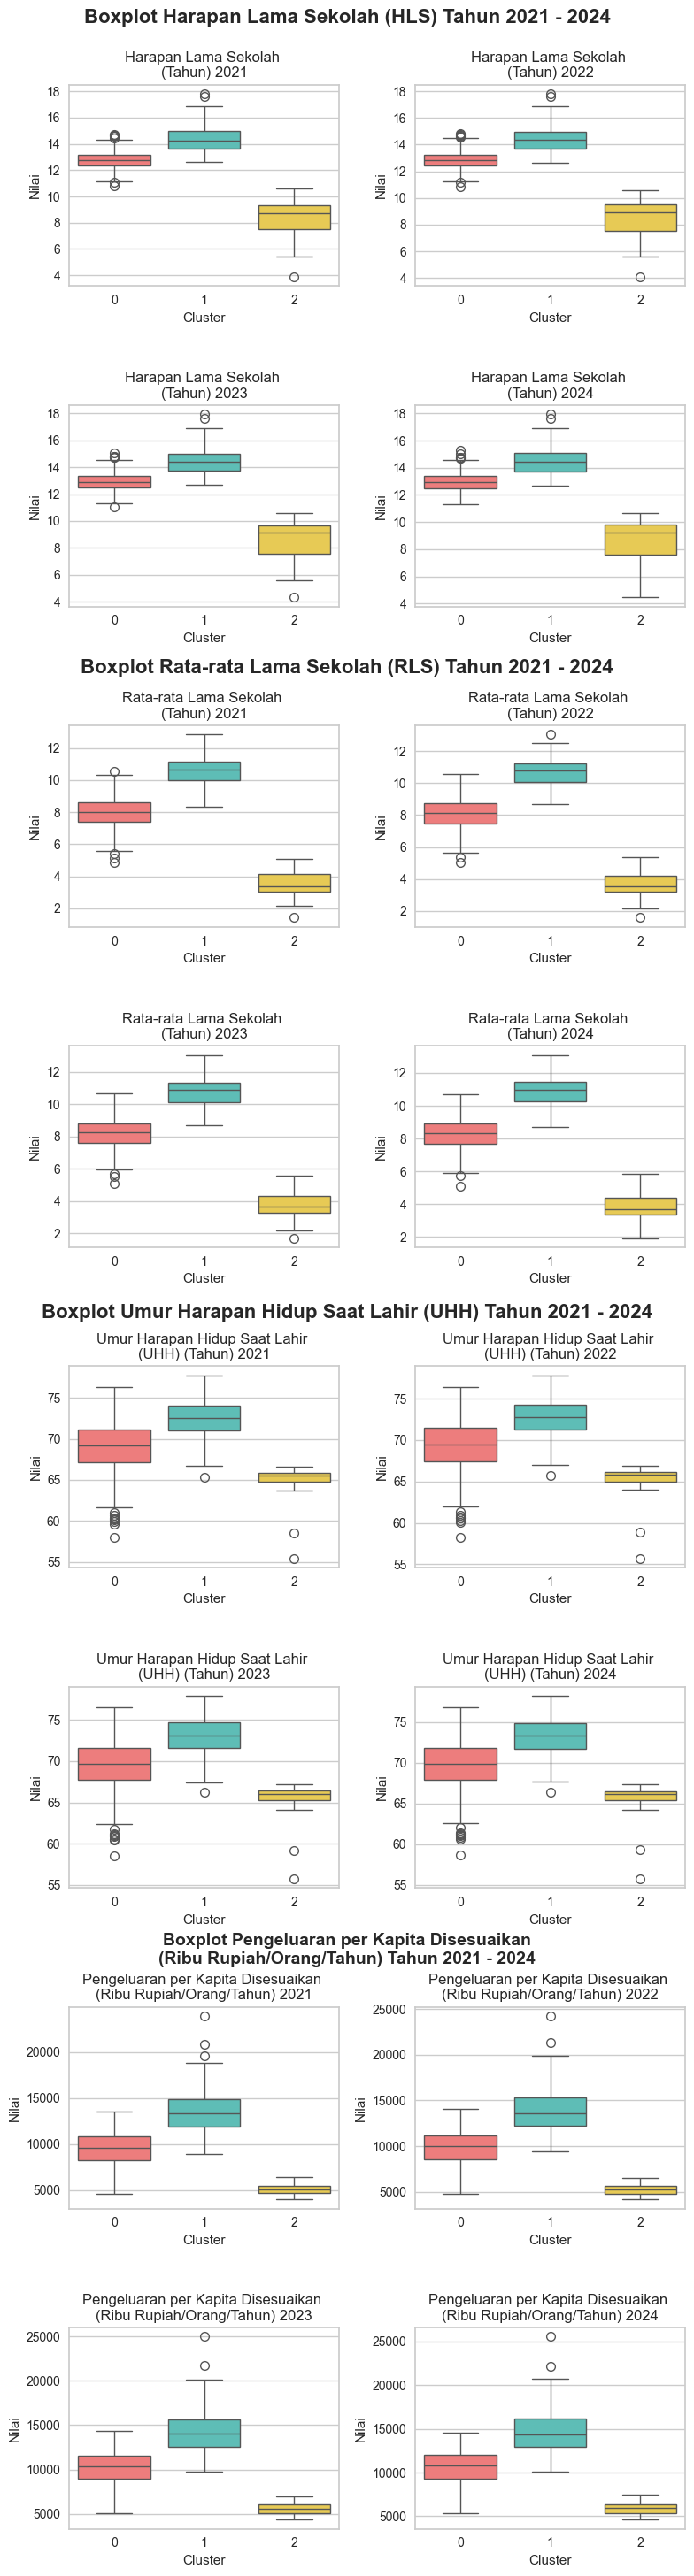

In [42]:
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

# warna = ['#FF6B6B', '#4ECDC4', '#FFD93D', '#6C5CE7', '#45B7D1']
warna = ['#FF6B6B', '#4ECDC4', '#FFD93D']
cols = df_visualize.columns
num_cols = len(df_visualize.columns)
# Mengatur ukuran plot dan jumlah subplot
# menampilkan box plot hanya untuk 4 tahun terakhir

offset = 11
fig, axes = plt.subplots(nrows=8, ncols=2, figsize=(8, 30))
# Sesuaikan jumlah baris dan kolom sesuai kebutuhan
axes = axes.flatten()
fig.text(0.5, 0.97, 'Boxplot Harapan Lama Sekolah (HLS) Tahun 2021 - 2024', ha='center', va='top', fontsize=16, fontweight='bold')
for i in range(offset, offset + 4):
    curr_ax = axes[i - offset]
    # Plot box plot pada subplot
    # print(cols[i])
    # ambil data mulai dari 4 tahun terakhir, tidak usah offset
    title = cols[i].replace("(", "\n(", 1)
    sns.boxplot(x=df_visualize['Cluster'], y= df_visualize[cols[i]], data=df_visualize, ax=curr_ax, palette=warna)
    curr_ax.set_title(title)
    curr_ax.set_xlabel('Cluster')
    curr_ax.set_ylabel('Nilai')

offset += 15
axes = axes.flatten()
fig.text(0.5, 0.725, 'Boxplot Rata-rata Lama Sekolah (RLS) Tahun 2021 - 2024', ha='center', va='top', fontsize=16, fontweight='bold')
for i in range(offset, offset + 4):
    curr_ax = axes[i - offset - 12]
    # Plot box plot pada subplot
    # print(cols[i])
    # ambil data mulai dari 4 tahun terakhir, tidak usah offset
    title = cols[i].replace("(", "\n(", 1)
    sns.boxplot(x=df_visualize['Cluster'], y= df_visualize[cols[i]], data=df_visualize, ax=curr_ax, palette=warna)
    curr_ax.set_title(title)
    curr_ax.set_xlabel('Cluster')
    curr_ax.set_ylabel('Nilai')

offset += 15
axes = axes.flatten()
fig.text(0.5, 0.482, 'Boxplot Umur Harapan Hidup Saat Lahir (UHH) Tahun 2021 - 2024', ha='center', va='top', fontsize=16, fontweight='bold')
for i in range(offset, offset + 4):
    curr_ax = axes[i - offset - 8]
    # Plot box plot pada subplot
    # print(cols[i])
    # ambil data mulai dari 4 tahun terakhir, tidak usah offset
    title = cols[i].replace("(", "\n(", 1)
    sns.boxplot(x=df_visualize['Cluster'], y= df_visualize[cols[i]], data=df_visualize, ax=curr_ax, palette=warna)
    curr_ax.set_title(title)
    curr_ax.set_xlabel('Cluster')
    curr_ax.set_ylabel('Nilai')

offset += 15
axes = axes.flatten()
fig.text(0.5, 0.245, 'Boxplot Pengeluaran per Kapita Disesuaikan\n(Ribu Rupiah/Orang/Tahun) Tahun 2021 - 2024', ha='center', va='top', fontsize=14, fontweight='bold')
for i in range(offset, offset + 4):
    curr_ax = axes[i - offset - 4]
    # Plot box plot pada subplot
    # print(cols[i])
    # ambil data mulai dari 4 tahun terakhir, tidak usah offset
    title = cols[i].replace("(", "\n(", 1)
    sns.boxplot(x=df_visualize['Cluster'], y= df_visualize[cols[i]], data=df_visualize, ax=curr_ax, palette=warna)
    curr_ax.set_title(title)
    curr_ax.set_xlabel('Cluster')
    curr_ax.set_ylabel('Nilai')

# # Mengatur layout agar lebih rapi
plt.tight_layout(rect=[0, 0, 1, 0.96], h_pad=3.2)
plt.savefig('images/boxplot.png', dpi=500)
plt.show()

In [43]:
df_indonesia = indonesia
df_indonesia['Cluster'] = 999
df_indonesia

,Harapan Lama Sekolah (Tahun) 2010,Harapan Lama Sekolah (Tahun) 2011,Harapan Lama Sekolah (Tahun) 2012,Harapan Lama Sekolah (Tahun) 2013,Harapan Lama Sekolah (Tahun) 2014,Harapan Lama Sekolah (Tahun) 2015,Harapan Lama Sekolah (Tahun) 2016,Harapan Lama Sekolah (Tahun) 2017,Harapan Lama Sekolah (Tahun) 2018,Harapan Lama Sekolah (Tahun) 2019,...,Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun) 2016,Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun) 2017,Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun) 2018,Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun) 2019,Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun) 2020,Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun) 2021,Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun) 2022,Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun) 2023,Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun) 2024,Cluster
Provinsi/Kabupaten/Kota/Indonesia,,,,,,,,,,,,,,,,,,,,,
INDONESIA,11.29,11.44,11.68,12.1,12.39,12.55,12.72,12.85,12.91,12.95,...,10420,10664,11059,11299,11013,11156,11479,11899,12341,999


['Harapan Lama Sekolah (Tahun) 2010', 'Harapan Lama Sekolah (Tahun) 2011', 'Harapan Lama Sekolah (Tahun) 2012', 'Harapan Lama Sekolah (Tahun) 2013', 'Harapan Lama Sekolah (Tahun) 2014', 'Harapan Lama Sekolah (Tahun) 2015', 'Harapan Lama Sekolah (Tahun) 2016', 'Harapan Lama Sekolah (Tahun) 2017', 'Harapan Lama Sekolah (Tahun) 2018', 'Harapan Lama Sekolah (Tahun) 2019', 'Harapan Lama Sekolah (Tahun) 2020', 'Harapan Lama Sekolah (Tahun) 2021', 'Harapan Lama Sekolah (Tahun) 2022', 'Harapan Lama Sekolah (Tahun) 2023', 'Harapan Lama Sekolah (Tahun) 2024', 'Rata-rata Lama Sekolah (Tahun) 2010', 'Rata-rata Lama Sekolah (Tahun) 2011', 'Rata-rata Lama Sekolah (Tahun) 2012', 'Rata-rata Lama Sekolah (Tahun) 2013', 'Rata-rata Lama Sekolah (Tahun) 2014', 'Rata-rata Lama Sekolah (Tahun) 2015', 'Rata-rata Lama Sekolah (Tahun) 2016', 'Rata-rata Lama Sekolah (Tahun) 2017', 'Rata-rata Lama Sekolah (Tahun) 2018', 'Rata-rata Lama Sekolah (Tahun) 2019', 'Rata-rata Lama Sekolah (Tahun) 2020', 'Rata-rata Lama

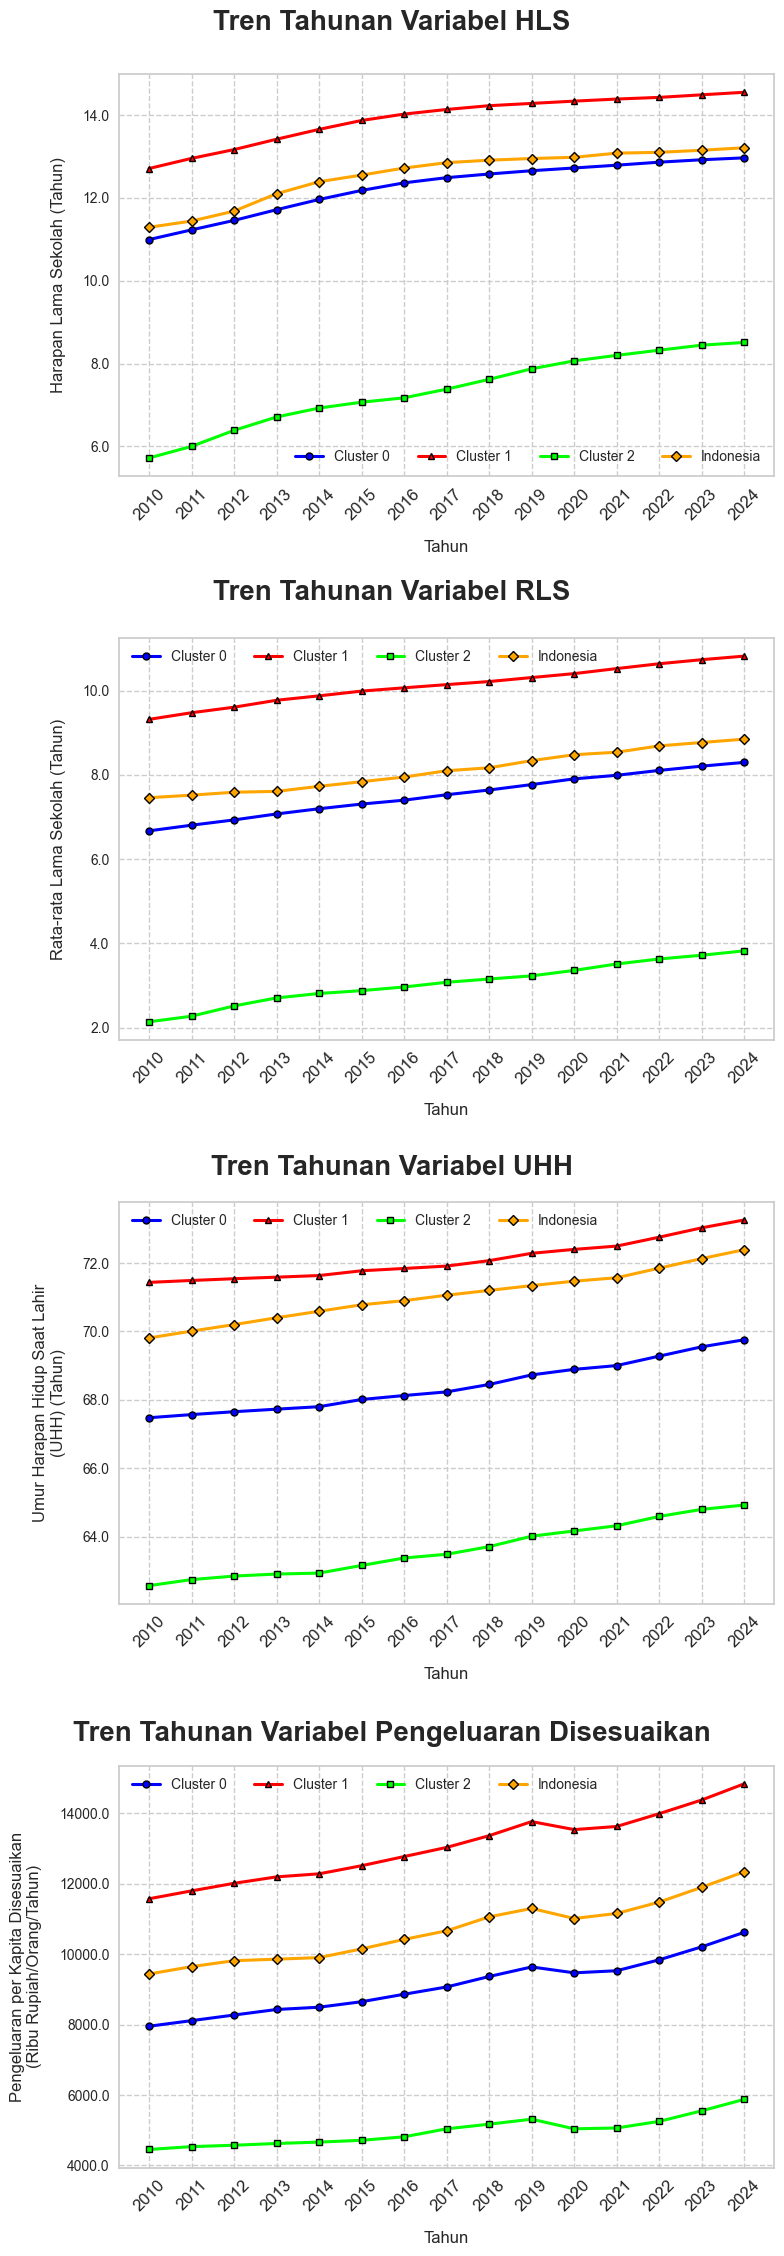

In [44]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

df = pd.read_excel('datasets/535240039.xlsx', sheet_name='Hasil', index_col='Provinsi/Kabupaten/Kota/Indonesia')

# blue_patch = mpatches.Patch(color='blue', label='Cluster 0')
# red_patch = mpatches.Patch(color='red', label='Cluster 1')
# lime_patch = mpatches.Patch(color='lime', label='Cluster 2')
df = pd.concat([df, df_indonesia])

print(df.columns.tolist())

cols_hls = [c for c in df.columns if 'Harapan Lama Sekolah (Tahun) ' in str(c)]
cols_rls = [c for c in df.columns if 'Rata-rata Lama Sekolah (Tahun) ' in str(c)]
cols_uhh = [c for c in df.columns if 'Umur Harapan Hidup Saat Lahir (UHH) (Tahun) ' in str(c)]
cols_pengeluaran = [c for c in df.columns if 'Pengeluaran per Kapita Disesuaikan (Ribu Rupiah/Orang/Tahun) ' in str(c)]

def extract_year(col_name):
    # "var <tahun>" -> tahun
    splitted = str(col_name).split()
    # print(splitted)
    return int(splitted[len(splitted) - 1])

# pastikan semua variable berperiode sama
years = [extract_year(c) for c in cols_hls]

cluster_colors = {0: 'blue', 1: 'red', 2: 'lime', 999: 'orange'}
cluster_labels = {0: 'Cluster 0', 1: 'Cluster 1', 2: 'Cluster 2', 999: 'Indonesia'}

# rata-rata kan per kolom (baris adalah kabupaten)
def compute_cluster_means(df, cols, cluster_col='Cluster'):
    result = {} # result[cluster]
    for c in df[cluster_col].unique():
        # nilai kolom dengan cluster yang diberikan
        subset = df[df[cluster_col] == c][cols].astype(float)
        # print(subset)
        result[c] = subset.mean(axis=0).values
    return result

rerata_hls = compute_cluster_means(df, cols_hls)
rerata_rls = compute_cluster_means(df, cols_rls)
rerata_uhh = compute_cluster_means(df, cols_uhh)
rerata_pengeluaran = compute_cluster_means(df, cols_pengeluaran)

fig, axes = plt.subplots(4, 1, figsize=(8, 23), sharex=False)
fig.text(0.5, 0.98, 'Tren Tahunan Variabel HLS', ha='center', va='top', fontsize=20, fontweight='bold')
fig.text(0.5, 0.732, 'Tren Tahunan Variabel RLS', ha='center', va='top', fontsize=20, fontweight='bold')
fig.text(0.5, 0.482, 'Tren Tahunan Variabel UHH', ha='center', va='top', fontsize=20, fontweight='bold')
fig.text(0.5, 0.236, 'Tren Tahunan Variabel Pengeluaran Disesuaikan', ha='center', va='top', fontsize=20, fontweight='bold')

datasets = [
    (axes[0], years, rerata_hls, 'Harapan Lama Sekolah (Tahun)'),
    (axes[1], years, rerata_rls, 'Rata-rata Lama Sekolah (Tahun)'),
    (axes[2], years, rerata_uhh, 'Umur Harapan Hidup Saat Lahir\n(UHH) (Tahun)'),
    (axes[3], years, rerata_pengeluaran, 'Pengeluaran per Kapita Disesuaikan\n(Ribu Rupiah/Orang/Tahun)')
]

markers = ['o', '^', 's', 'D']

marker_idx = -1
for ax, years, means, ylabel in datasets:
    for label in sorted(means.keys()):
        marker_idx += 1
        ax.plot(
            years,
            means[label],
            marker=markers[marker_idx],
            linewidth=2.2,
            markersize=5,
            markeredgecolor='black',
            markeredgewidth=1,
            color=cluster_colors[label],
            label=cluster_labels[label],
        )

    marker_idx = -1

    ax.set_ylabel(ylabel, fontsize=12, labelpad=12)
    ax.set_xlabel('Tahun', fontsize=12, labelpad=12)
    ax.set_xticks(years)
    ax.set_xticklabels([str(y) for y in years], ha='center', fontsize=12, rotation=45)
    ax.legend(fontsize=12)
    ax.grid(True, linestyle='--', alpha=1)
    ax.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.1f'))

for ax in axes:
    ax.legend(ncol=4, fontsize=10)

plt.tight_layout(rect=[0, 0, 1, 0.96], h_pad=5.0)
plt.savefig('images/trends.png', dpi=560)
plt.show()